# Use of LLMs

Publication-oriented descriptive visualizations of the developer survey. Each notebook reads the Excel workbook from **the same folder as the notebook** and saves vector PDFs and high-resolution PNGs under `figures/use_of_llms/`.

- The source workbook is not modified.
- Frequencies are calculated from the data at execution time (not hard-coded).
- For single-choice questions, percentages use valid responses to that question; missing answers are reported separately.
- For multi-select questions, percentages are percentages of respondents, so they need **not** sum to 100%.
- Category labels are taken directly from the survey; manual recoding is avoided.


In [1]:
FOLDER = 'use_of_llms'
from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator, PercentFormatter

# Put the original .xlsx alongside this notebook.
EXCEL_FILE = None  # Optionally specify a filename, e.g. "survey.xlsx"
ROOT = Path.cwd()
files = sorted(p for p in ROOT.glob("*.xlsx") if not p.name.startswith("~$"))
if EXCEL_FILE is None:
    if len(files) != 1:
        raise FileNotFoundError(f"Expected exactly one .xlsx alongside the notebook, found {len(files)}: {[p.name for p in files]}. Set EXCEL_FILE above.")
    excel_path = files[0]
else:
    excel_path = ROOT / EXCEL_FILE
raw = pd.read_excel(excel_path)
N = len(raw)
FIG_DIR = ROOT / "figures" / FOLDER
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Restrained, colorblind-conscious palette. All charts use the same styling.
INK = '#202a34'
BLUE = '#396ba4'
TEAL = '#368a82'
PALE = '#e7ebef'
PALETTE = ['#4878a8', '#6c91b6', '#8bb7ad', '#d9b26f', '#ba7383', '#857cae', '#8e9eab']
plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 9.5, 'axes.labelsize': 9.5,
    'axes.titlesize': 11, 'axes.titleweight': 'semibold',
    'axes.edgecolor': '#bfc6ce', 'axes.labelcolor': INK,
    'text.color': INK, 'xtick.color': INK, 'ytick.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'savefig.facecolor': 'white', 'pdf.fonttype': 42, 'ps.fonttype': 42,
})

def col(index):
    """Index is from the original workbook (0-based), to avoid ambiguity in long survey questions."""
    return raw.iloc[:, index]

def wrap(value, width=43):
    return '\n'.join(textwrap.wrap(str(value), width=width, break_long_words=False, break_on_hyphens=False))

def save_plot(fig, slug):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG_DIR / f'{slug}.{ext}', bbox_inches='tight',
                    dpi=350 if ext == 'png' else None, pad_inches=0.16)
    plt.show()
    plt.close(fig)

def single(index, title, slug, order=None, labels=None):
    series = col(index).dropna().astype(str).str.strip()
    counts = series.value_counts()
    if order is not None:
        counts = counts.reindex([key for key in order if key in counts.index], fill_value=0)
        other = series.value_counts().drop(index=counts.index, errors='ignore')
        counts = pd.concat([counts, other])
    if labels is not None:
        counts.index = [labels.get(k, k) for k in counts.index]
    denom = len(series)
    values = 100 * counts / denom
    labels_wrapped = [wrap(k) for k in counts.index]
    fig, ax = plt.subplots(figsize=(8.4, max(2.7, len(counts)*0.52 + 0.7)))
    pos = np.arange(len(counts))
    ax.barh(pos, values, color=BLUE, height=.69)
    ax.set_yticks(pos, labels_wrapped)
    ax.invert_yaxis()
    ax.set_xlim(0, max(30, np.ceil(values.max()/10)*10 + 12))
    ax.set_xlabel('Respondents (%)')
    ax.set_title(title, loc='left', pad=14)
    ax.xaxis.set_major_locator(MultipleLocator(20))
    ax.grid(axis='x', color=PALE, lw=.7)
    ax.set_axisbelow(True)
    ax.tick_params(axis='y', length=0, pad=8)
    for i, (pct, count) in enumerate(zip(values, counts)):
        ax.text(pct + 0.8, i, f'{pct:.1f}%  (n={count})', va='center', fontsize=8.1)
    fig.text(.99, .005, f'Valid n={denom}; missing n={N-denom}', ha='right', fontsize=8, color='#5d6872')
    fig.tight_layout(rect=(0, .025, 1, 1))
    save_plot(fig, slug)
    return counts

def multiple(index, title, slug, top=None):
    valid = col(index).dropna().astype(str)
    # Survey exports use comma-space delimiters for checkbox items.
    choices = valid.apply(lambda s: list(dict.fromkeys(x.strip() for x in s.split(', ') if x.strip())))
    counts = pd.Series([choice for row in choices for choice in row]).value_counts()
    if top is not None:
        counts = counts.head(top)
    counts = counts.sort_values()
    vals = counts * 100 / len(valid)
    fig, ax = plt.subplots(figsize=(9.0, max(3.1, len(counts)*.37 + .85)))
    y = np.arange(len(counts))
    ax.barh(y, vals, color=TEAL, height=.73)
    ax.set_yticks(y, [wrap(s, 46) for s in counts.index])
    ax.tick_params(axis='y', length=0, pad=8)
    ax.set_xlim(0, max(30, np.ceil(vals.max()/10)*10 + 10))
    ax.set_xlabel('Respondents selecting the option (%)')
    ax.set_title(title, loc='left', pad=14)
    ax.xaxis.set_major_locator(MultipleLocator(20))
    ax.grid(axis='x', color=PALE, lw=.7)
    ax.set_axisbelow(True)
    for i, (v, count) in enumerate(zip(vals, counts)):
        ax.text(v + .75, i, f'{v:.1f}% (n={count})', va='center', fontsize=8)
    fig.text(.99, .005, f'Multiple selections permitted; valid n={len(valid)}; missing n={N-len(valid)}',
             ha='right', fontsize=8, color='#5d6872')
    fig.tight_layout(rect=(0, .026, 1, 1))
    save_plot(fig, slug)
    return counts

# print(f'Workbook: {excel_path.name} | Respondents: {N} | Output: {FIG_DIR}')
print(f'Workbook: {excel_path.name} | Respondents: {N}')



Workbook: developers-answers.xlsx | Respondents: 104


## Frequency of using coding assistants

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


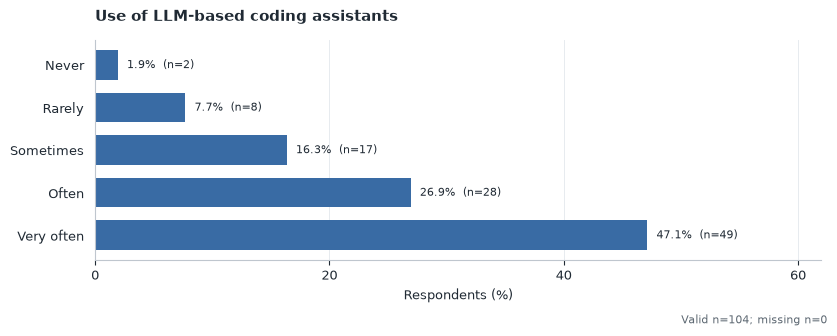

Do you use LLM-based coding assistants as part of your software development activities?
Never          2
Rarely         8
Sometimes     17
Often         28
Very often    49
Name: count, dtype: int64

In [2]:
single(12, 'Use of LLM-based coding assistants', 'llm_use_frequency', order=['Never','Rarely','Sometimes','Often','Very often'])

## Activities supported by LLMs (multiple selections)

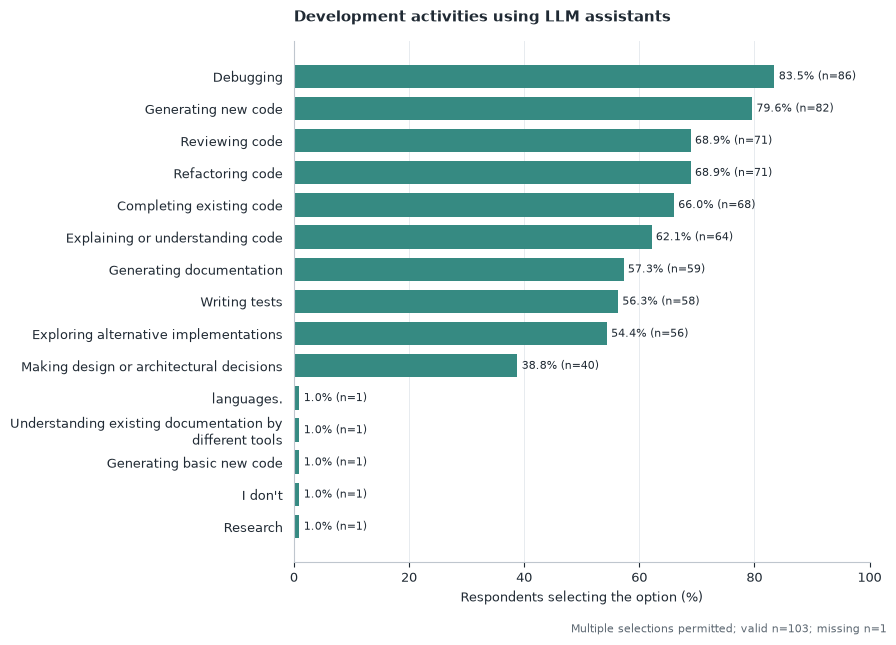

Research                                                    1
I don't                                                     1
Generating basic new code                                   1
Understanding existing documentation by different tools     1
languages.                                                  1
Making design or architectural decisions                   40
Exploring alternative implementations                      56
Writing tests                                              58
Generating documentation                                   59
Explaining or understanding code                           64
Completing existing code                                   68
Refactoring code                                           71
Reviewing code                                             71
Generating new code                                        82
Debugging                                                  86
Name: count, dtype: int64

In [3]:
multiple(13, 'Development activities using LLM assistants', 'llm_activities')

## Acceptance of generated code

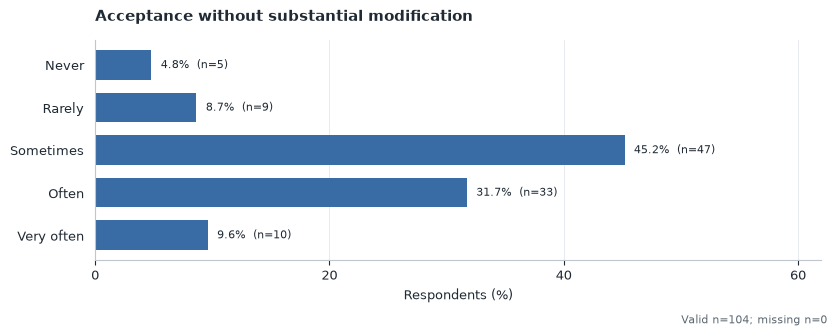

On average, when using an LLM-based coding assistant, how often do you accept the implementation proposed by the tool without substantial modification?
Never          5
Rarely         9
Sometimes     47
Often         33
Very often    10
Name: count, dtype: int64

In [4]:
single(14, 'Acceptance without substantial modification', 'llm_acceptance', order=['Never','Rarely','Sometimes','Often','Very often'])

## Perceived delegation of implementation choices

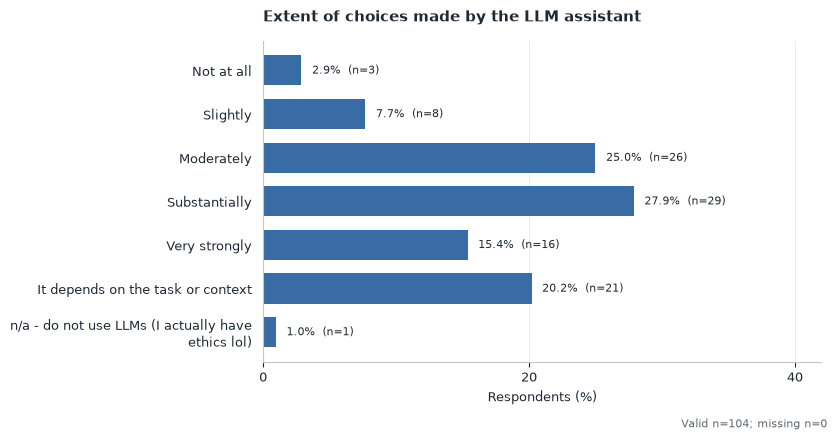

To what extent do you feel the coding assistant makes implementation choices that you would otherwise make yourself?
Not at all                                             3
Slightly                                               8
Moderately                                            26
Substantially                                         29
Very strongly                                         16
It depends on the task or context                     21
n/a - do not use LLMs (I actually have ethics lol)     1
Name: count, dtype: int64

In [5]:
single(16, 'Extent of choices made by the LLM assistant', 'llm_discretion', order=['Not at all','Slightly','Moderately','Substantially','Very strongly','It depends on the task or context'])

## Agency and oversight when using LLMs

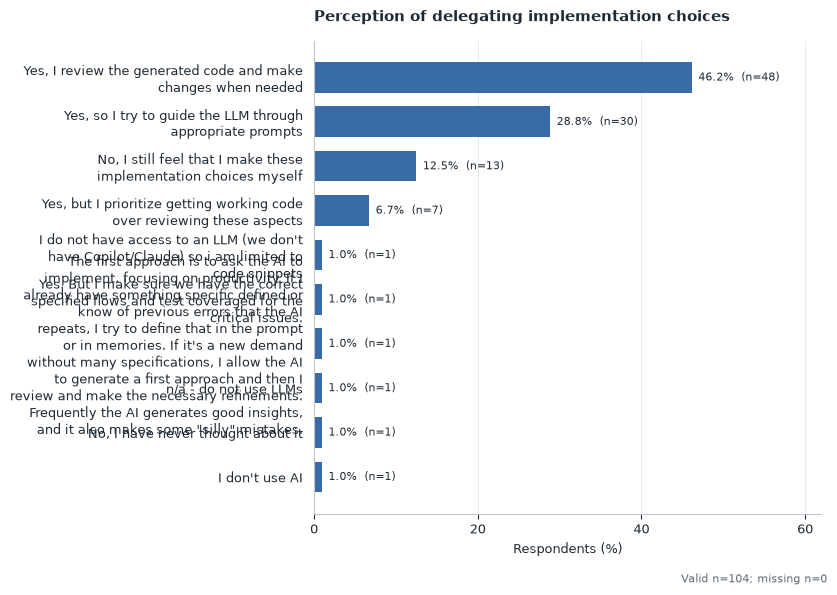

When using an LLM, do you feel that you are delegating some of these implementation choices to the LLM?
Yes, I review the generated code and make changes when needed                                                                                                                                                                                                                                                                                                                                                                                                          48
Yes, so I try to guide the LLM through appropriate prompts                                                                                                                                                                                                                                                                                                                                                                                            

In [6]:
single(31, 'Perception of delegating implementation choices', 'llm_agency')

## Open-ended acceptance criteria

In [7]:
# Question 15 mixes YES/NO with free-text explanations.
# Preserve the original answers; a yes/no classification requires manual coding.
answers = col(15).dropna()
print(f'Functional-correctness acceptance explanations: {len(answers)} nonempty answers')
print('Not plotted: these responses require a documented coding scheme to avoid conflating explanations with response categories.')

Functional-correctness acceptance explanations: 104 nonempty answers
Not plotted: these responses require a documented coding scheme to avoid conflating explanations with response categories.


**Reproducibility note.** Outputs are descriptive (no inferential statistics). Text responses are intentionally not treated as quantitative categories; the plots only aggregate closed-ended questions. Denominators and missing-response counts are shown in each figure.